# INF792 – Trabalho Final
## Visualização didática do Algoritmo de Harris (Harris Corner Detection)

**Autor:** Werikson Frederiko de Oliveira Alves  
**Disciplina:** INF792 – Fundamentos de Visão Computacional  

---

## Objetivos do notebook

O objetivo deste notebook é **explicar visualmente, passo a passo**, o funcionamento do algoritmo de detecção de cantos de Harris, focando em:

- O que é um **canto** em uma imagem e por que ele é útil em visão computacional;
- Como o algoritmo de Harris utiliza **gradientes de intensidade** e a **matriz de estrutura** (autocorrelação local);
- Como calcular e interpretar a **resposta de Harris** \(R\);
- Como aplicar **limiarização (thresholding)** e **non-maximum suppression** para obter os cantos finais;
- Como visualizar e interpretar os **resultados intermediários** em cada etapa do pipeline.

## 1. Revisão teórica do algoritmo de Harris

### 1.1. O que é um canto?

Em uma imagem em tons de cinza, um **canto** (corner) é um ponto em que a intensidade muda **significativamente em mais de uma direção**.

- Em uma **região plana**, mover uma pequena janela em qualquer direção quase não altera a intensidade.
- Em uma **borda**, mover a janela **perpendicularmente** à borda causa grande variação, mas ao longo da borda a variação é pequena.
- Em um **canto**, ao deslocarmos a janela em praticamente qualquer direção, a variação de intensidade tende a ser grande.

O algoritmo de Harris formaliza essa intuição usando uma **função de variação** que mede quanto a intensidade muda ao deslocar uma pequena janela sobre a imagem.

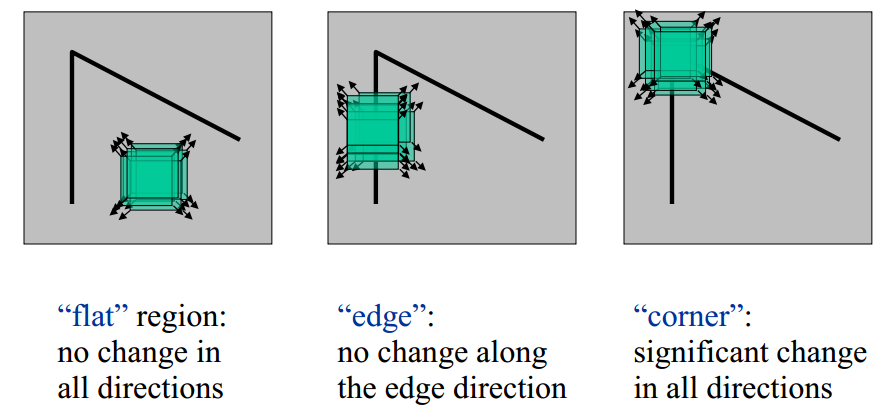

---

### 1.2. Formulação matemática resumida

Dada uma imagem em tons de cinza $I(x, y)$ e uma janela de ponderação $w(x, y)$, definimos a função:

$$
E(u, v) = \sum_{x, y} w(x, y)\,\big(I(x+u, y+v) - I(x, y)\big)^2
$$

Para deslocamentos pequenos, usamos uma aproximação de Taylor de primeira ordem:

$$
I(x+u, y+v) \approx I(x, y) + I_x u + I_y v
$$

onde $I_x$ e $I_y$ são as derivadas parciais (gradientes da imagem).

Substituindo em $E(u, v)$, obtemos:

$$
E(u,v) \approx 
\begin{bmatrix} u & v \end{bmatrix}
M(x,y)
\begin{bmatrix} u \\ v \end{bmatrix}
$$

em que $M(x,y)$ é a **matriz de estrutura** (ou matriz de autocorrelação local):

$$
M(x,y) = \sum_{x,y} w(x, y)
\begin{bmatrix}
I_x^2 & I_x I_y \\
I_x I_y & I_y^2
\end{bmatrix}
$$

Os autovalores $\lambda_1, \lambda_2$ de $M$ indicam o tipo de região:

- $\lambda_1 \approx 0$ e $\lambda_2 \approx 0$: região **plana**;
- um grande e outro pequeno: **borda**;
- ambos grandes: **canto**.

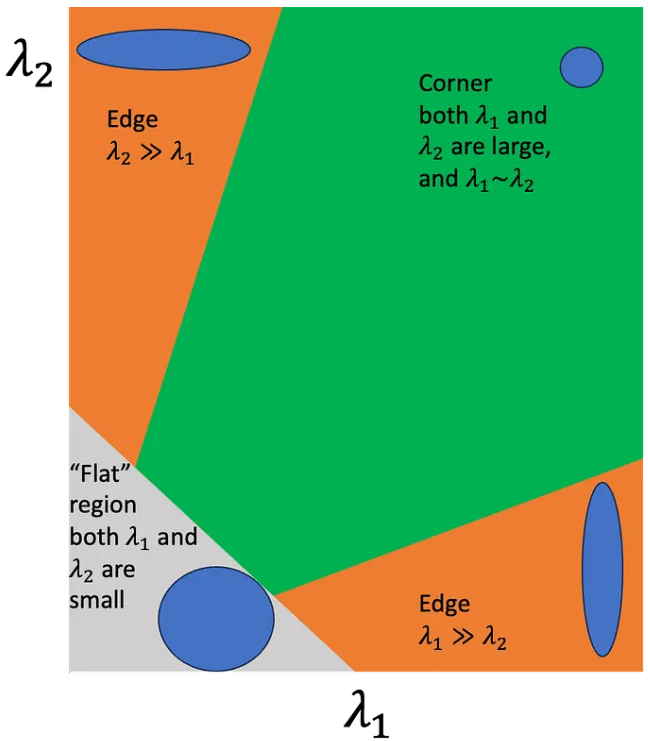

---

### 1.3. Resposta de Harris

Para evitar calcular explicitamente os autovalores, o algoritmo de Harris define a função:

$$
R = \det(M) - k \cdot \big(\text{trace}(M)\big)^2
$$

com:

- $\det(M) = \lambda_1 \lambda_2$
- $\text{trace}(M) = \lambda_1 + \lambda_2$
- $k \in [0.0, 0.1]$ (parâmetro empírico)

Interpretação de $R$:

- $R \gg 0$: provável **canto**;
- $R < 0$: provavelmente **borda**;
- $R \approx 0$: **região plana**.

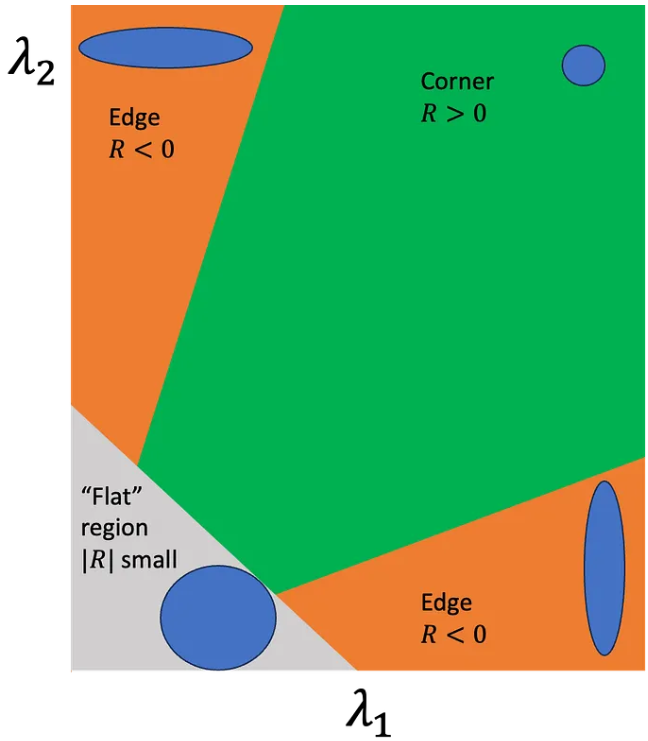

---

## 2. Implementação passo a passo

A partir deste ponto, vamos seguir um pipeline bem definido:

1. **Etapa 1** – Leitura e pré-processamento da imagem  
2. **Etapa 2** – Cálculo dos gradientes $I_x$ e $I_y$  
3. **Etapa 3** – Construção da matriz de estrutura $M$ (via produtos e suavização)  
4. **Etapa 4** – Cálculo da resposta de Harris $R$  
5. **Etapa 5** – Limiarização, non-maximum suppression e exibição dos cantos

Em cada etapa, teremos:

- Uma breve explicação em texto;
- Uma célula de código chamando funções do módulo `harris_core.py`;
- Uma figura mostrando o resultado intermediário.

Isso ajuda a enxergar **como o algoritmo é construído em camadas**, em vez de tratá-lo como uma “caixa preta”.


In [1]:
import matplotlib.pyplot as plt

from harris_core import (
    show_image,
    show_side_by_side,
    load_and_preprocess_image,
    compute_image_gradients,
    compute_structure_tensor,
    compute_harris_response,
    detect_corners,
    overlay_corners_on_image,
    show_gradients,
    show_structure_tensor_components,
    show_harris_response,
)

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"


### Etapa 1 – Leitura e pré-processamento da imagem

Nesta etapa, vamos:

1. Carregar uma imagem de teste (por exemplo, um tabuleiro de xadrez ou uma cena com muitos cantos);
2. Converter a imagem para tons de cinza;
3. Aplicar uma suavização Gaussiana para reduzir ruídos antes do cálculo dos gradientes.

A ideia é ter uma imagem **“limpa” o suficiente** para que os gradientes representem principalmente **estruturas relevantes** (bordas, cantos) e não apenas ruído de alta frequência.


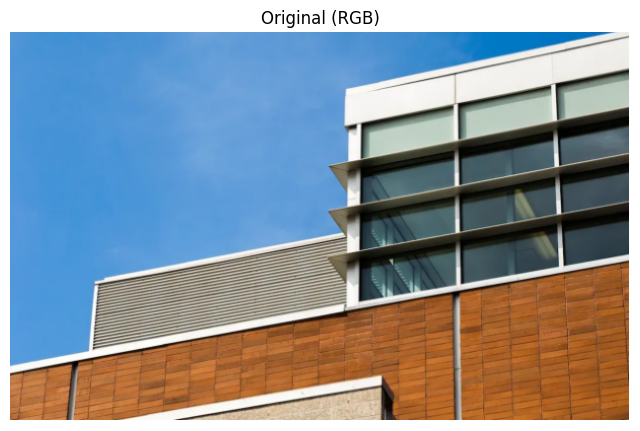

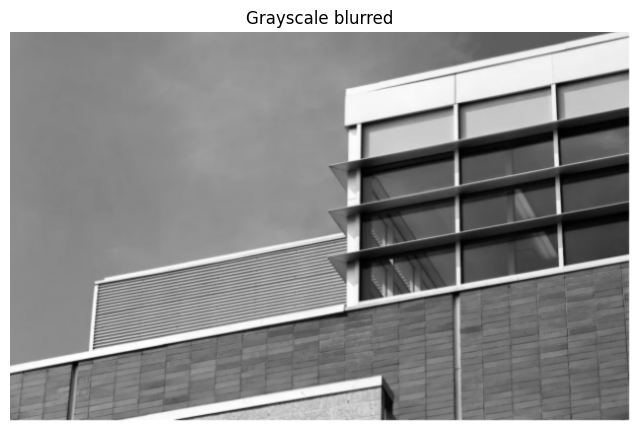

In [2]:
image_path = "images/img_validation.png"
rgb, gray_blur = load_and_preprocess_image(image_path, sigma=0.50)

show_image("Original (RGB)", rgb)
show_image("Grayscale blurred", gray_blur, cmap="gray")


### Etapa 2 – Cálculo dos gradientes da imagem

O próximo passo é calcular os gradientes **horizontais** $I_x$ e **verticais** $I_y$.

Usaremos filtros de Sobel para aproximar as derivadas:

- $I_x = \frac{\partial I}{\partial x} \qquad$ e $\qquad I_y = \frac{\partial I}{\partial y}$

Com esses gradientes, podemos visualizar:

- Onde há variação de intensidade (bordas);
- Em qual direção essa variação é maior (informação de orientação).

Esses gradientes serão usados para construir a **matriz de estrutura**.


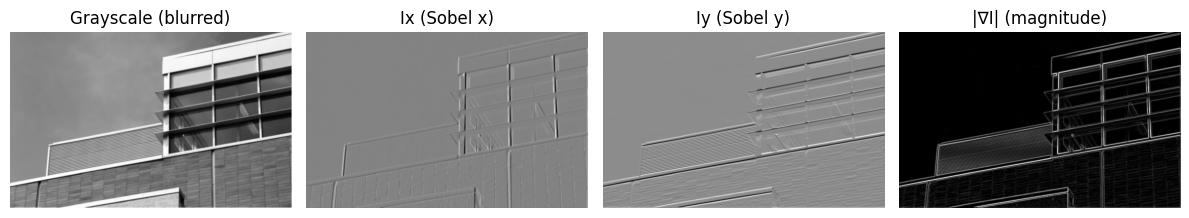

In [3]:
ix, iy = compute_image_gradients(gray_blur)
show_gradients(gray_blur, ix, iy)


### Etapa 3 – Matriz de estrutura (autocorrelação)

Com os gradientes $I_x$ e $I_y$ em cada pixel, construímos os seguintes produtos:

- $I_x^2, \qquad$ $\qquad I_y^2 \qquad$ e $\qquad I_x I_y$

Depois, aplicamos uma **suavização Gaussiana** nesses produtos, o que equivale a usar uma janela $w(x, y)$ para computar a matriz de estrutura $M(x, y)$:

$$
M(x,y) =
\begin{bmatrix}
\sum w I_x^2 & \sum w I_x I_y \\ \\
\sum w I_x I_y & \sum w I_y^2
\end{bmatrix}
$$

Nesta etapa, vamos visualizar os mapas de $I_x^2, I_y^2, I_x I_y$ (já suavizados), que representam como a variação local da intensidade está distribuída em cada região da imagem.


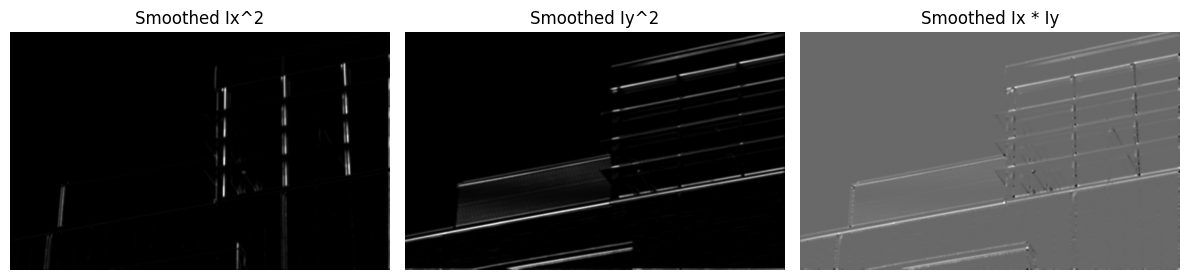

In [4]:
s_ix2, s_iy2, s_ixy = compute_structure_tensor(ix, iy, window_sigma=1)
show_structure_tensor_components(s_ix2, s_iy2, s_ixy)


### Etapa 4 – Cálculo da resposta de Harris

Agora, para cada pixel, construímos a **resposta de Harris**:

$$
R = \det(M) - k \cdot \big(\text{trace}(M)\big)^2
$$

onde:

- $\det(M) = M_{11} M_{22} - M_{12}^2$;
- $\text{trace}(M) = M_{11} + M_{22}$;
- $k$ é um parâmetro empírico (tipicamente entre 0.04 e 0.06).

Vamos implementar essa fórmula e visualizar o mapa de $R$ como um **heatmap**, para ver:

- regiões onde $R$ é **positivo e alto** (bons candidatos a cantos);
- regiões onde $R$ é **negativo** (tipicamente bordas);
- regiões onde $R$ está próximo de zero (regiões planas).

Essa visualização ajuda a entender como o algoritmo “enxerga” cantos na imagem.


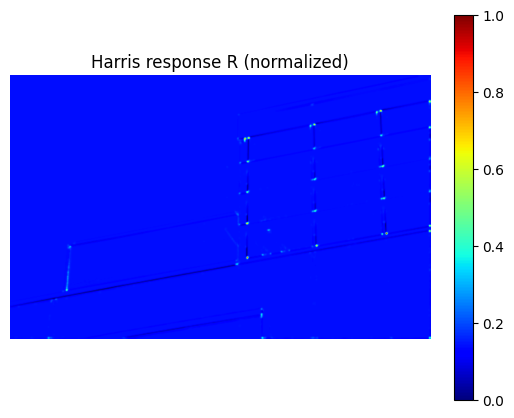

In [5]:
r = compute_harris_response(s_ix2, s_iy2, s_ixy, k=0.02)
show_harris_response(r)


### Etapa 5 – Detecção final de cantos

A partir do mapa de resposta $R$, precisamos:

1. **Normalizar** $R$ para uma faixa adequada (por exemplo, $[0, 1]$);
2. Aplicar um **limiar (threshold)** para descartar respostas fracas;
3. Aplicar **non-maximum suppression** para manter apenas os máximos locais (evitando marcar vários pixels muito próximos representando o mesmo canto).

O resultado final será um conjunto de pontos (pixels) marcados como **cantos**, que vamos sobrepor à imagem original. Se diminuirmos esse valor, vamos ter mais cantos (incluindo falsos positivos); se aumentarmos, vamos ter menos cantos, apenas os mais fortes.

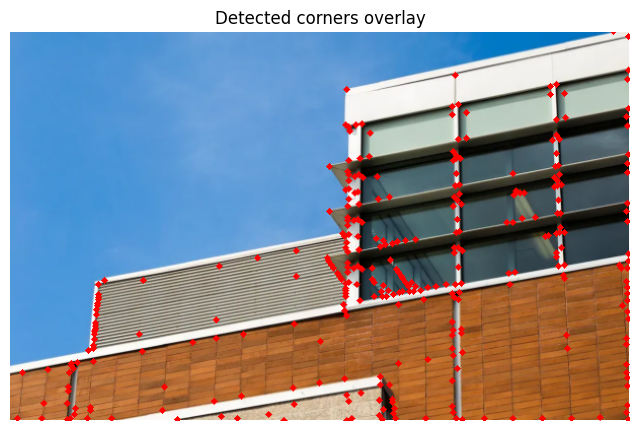

In [6]:

corner_mask = detect_corners(r, threshold_ratio=0.14)
overlay = overlay_corners_on_image(rgb, corner_mask, marker_color=(255, 0, 0), marker_size=1)
show_image("Detected corners overlay", overlay)


## 3. Conclusão

Neste notebook, implementamos e visualizamos passo a passo o algoritmo de **Harris Corner Detection**:

- Começamos definindo o que é um **canto** e revisando a formulação matemática baseada na matriz de estrutura $M$;
- Calculamos os **gradientes** da imagem e construímos os termos $I_x^2, I_y^2, I_x I_y$;
- Suavizamos esses termos para obter a matriz de estrutura em cada ponto;
- Aplicamos a **resposta de Harris** $R = \det(M) - k \cdot (\text{trace}(M))^2$;
- Realizamos **limiarização** e **non-maximum suppression** para obter um conjunto final de cantos;
- Sobrepusemos os cantos na imagem original, facilitando a interpretação visual.